FileNotFoundError: [Errno 2] No such file or directory: '../dataset/samples/contoh_gangguan.png'

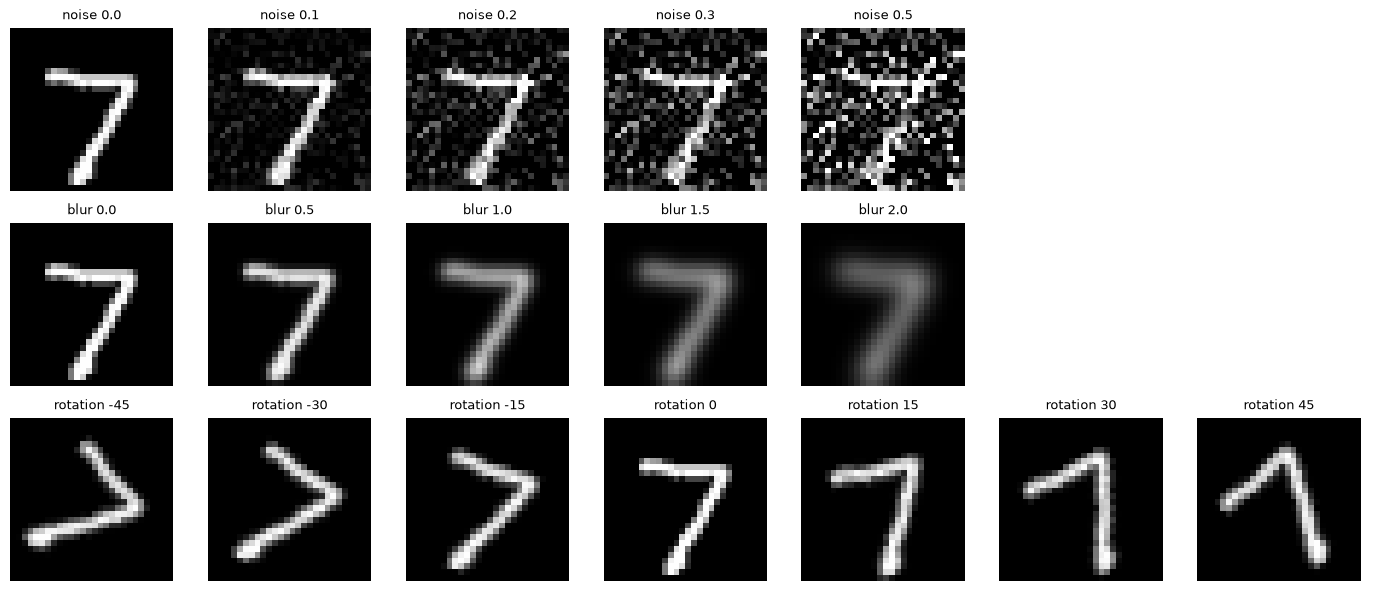

In [1]:
import numpy as np, matplotlib.pyplot as plt
from pathlib import Path

D = Path('..') / 'dataset' / 'perturbed'
fig, axes = plt.subplots(3, 7, figsize=(14, 6))
for row, name in enumerate(['noise', 'blur', 'rotation']):
    d = np.load(D / f'{name}.npz')
    for col in range(7):
        ax = axes[row, col]; ax.axis('off')
        if col < len(d['levels']):
            ax.imshow(d['X'][col, 0, :, :, 0], cmap='gray', vmin=0, vmax=255)
            ax.set_title(f"{name} {d['levels'][col]}", fontsize=9)
plt.tight_layout()
plt.savefig('../dataset/samples/contoh_gangguan.png', dpi=150)
plt.show()

In [1]:
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix

D = Path('../dataset/perturbed'); FIG = Path('../report/figures')
model = tf.keras.models.load_model('model_cnn_mnist.keras')

In [2]:
results = {}
for name in ['noise', 'blur', 'rotation']:
    d = np.load(D / f'{name}.npz')
    y = to_categorical(d['y'], 10)
    accs = []
    for i, lv in enumerate(d['levels']):
        X = d['X'][i].astype('float32') / 255.0      # penting: bagi 255
        accs.append(model.evaluate(X, y, verbose=0)[1])
    results[name] = (d['levels'], np.array(accs))
    print(name)
    for lv, a in zip(d['levels'], accs): print(f'  level {lv}: {a:.4f}')

noise
  level 0.0: 0.9874
  level 0.1: 0.9849
  level 0.2: 0.9781
  level 0.3: 0.9436
  level 0.5: 0.6287
blur
  level 0.0: 0.9874
  level 0.5: 0.9868
  level 1.0: 0.9830
  level 1.5: 0.9667
  level 2.0: 0.9226
rotation
  level -45: 0.4635
  level -30: 0.7795
  level -15: 0.9589
  level 0: 0.9874
  level 15: 0.9667
  level 30: 0.8299
  level 45: 0.5480


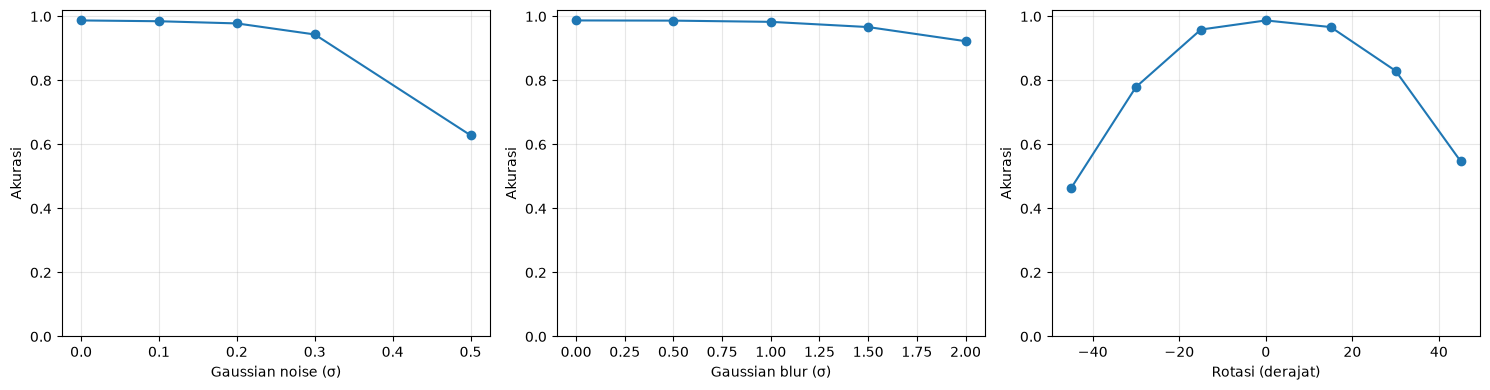

In [3]:
titles = {'noise':'Gaussian noise (σ)', 'blur':'Gaussian blur (σ)', 'rotation':'Rotasi (derajat)'}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, name in zip(ax, results):
    lv, acc = results[name]
    a.plot(lv, acc, 'o-'); a.set_xlabel(titles[name]); a.set_ylabel('Akurasi')
    a.set_ylim(0, 1.02); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG/'akurasi_vs_gangguan.png', dpi=150); plt.show()

In [4]:
for name, (lv, acc) in results.items():
    print(f'| {name} | ' + ' | '.join(f'{l}' for l in lv) + ' |')
    print('| Akurasi | ' + ' | '.join(f'{a*100:.2f}%' for a in acc) + ' |\n')

| noise | 0.0 | 0.1 | 0.2 | 0.3 | 0.5 |
| Akurasi | 98.74% | 98.49% | 97.81% | 94.36% | 62.87% |

| blur | 0.0 | 0.5 | 1.0 | 1.5 | 2.0 |
| Akurasi | 98.74% | 98.68% | 98.30% | 96.67% | 92.26% |

| rotation | -45 | -30 | -15 | 0 | 15 | 30 | 45 |
| Akurasi | 46.35% | 77.95% | 95.89% | 98.74% | 96.67% | 82.99% | 54.80% |



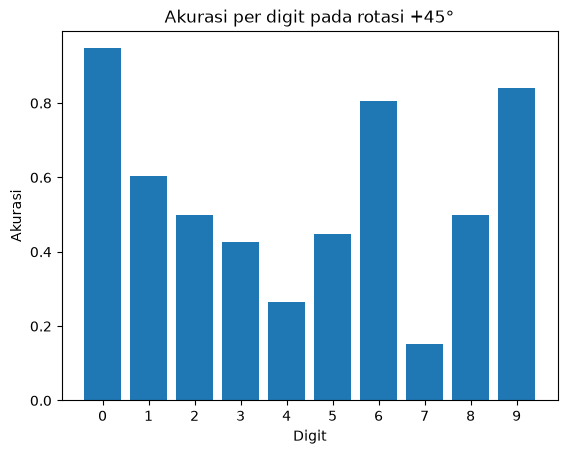

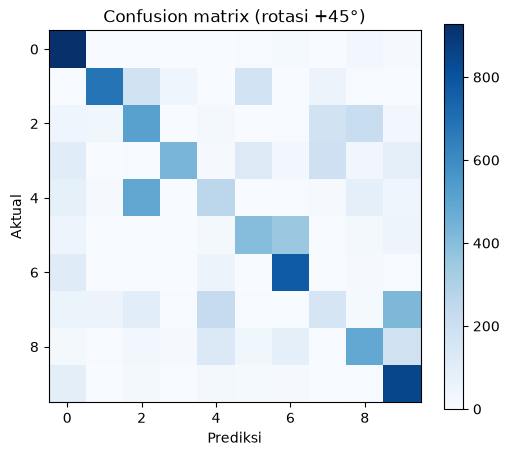

In [5]:
d = np.load(D / 'rotation.npz'); X = d['X'][-1].astype('float32')/255.0   # rotasi +45°
pred = np.argmax(model.predict(X, verbose=0), axis=1); true = d['y']
per_digit = [(pred[true==k]==k).mean() for k in range(10)]
plt.bar(range(10), per_digit); plt.xticks(range(10)); plt.xlabel('Digit'); plt.ylabel('Akurasi')
plt.title('Akurasi per digit pada rotasi +45°')
plt.savefig(FIG/'akurasi_per_digit_rot45.png', dpi=150); plt.show()

cm = confusion_matrix(true, pred)
plt.figure(figsize=(6,5)); plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.title('Confusion matrix (rotasi +45°)')
plt.savefig(FIG/'confusion_rot45.png', dpi=150); plt.show()

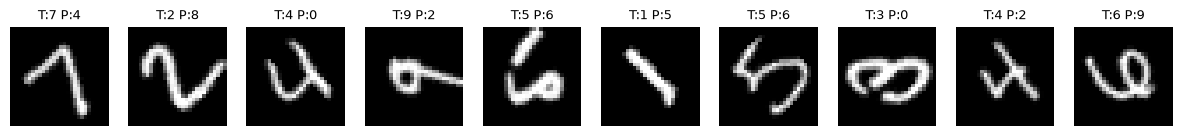

In [6]:
wrong = np.where(pred != true)[0][:10]
fig, ax = plt.subplots(1, 10, figsize=(15, 2))
for a, i in zip(ax, wrong):
    a.imshow(X[i,...,0], cmap='gray'); a.set_title(f'T:{true[i]} P:{pred[i]}', fontsize=9); a.axis('off')
plt.savefig(FIG/'contoh_salah_rot45.png', dpi=150, bbox_inches='tight'); plt.show()